# Reto 4 · Interpretación de los segmentos

**Clustering the Star — Mercedes-Benz · III Malackathon 2026**

Objetivo: traducir los 6 clusters del Reto 3 a **perfiles de cliente** que un equipo de marketing pueda entender y
usar, cada uno con un **nombre**, sus **rasgos** y **acciones comerciales** concretas.

Para perfilar usamos dos tipos de variables:
- las **12 features del modelo**, en sus **unidades reales** (años, %, nº de vehículos), no escaladas;
- **variables de perfilado** que no entraron en el modelo: país, género, B2B, AMG, modelos, motorización,
  consentimientos por canal y telemetría.

Antes de poner nombres se comprueban las **trampas de interpretación** más probables (apartado 3).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

from features import (cargar_datos, construir_pipeline, ajustar_kmeans, nombrar_segmentos, ORDEN_SEGMENTOS,
                      COLORES_SEGMENTOS, FEATURES, ORDEN_EDAD, SEMILLA, N_INIT_FINAL)

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.1f}".format)
pd.set_option("display.width", 200)

df = cargar_datos()
pipe = construir_pipeline()
X = pipe.fit_transform(df)
clientes = pipe.named_steps["agregar"].transform(df)
km = ajustar_kmeans(X)
clientes["cluster"] = km.labels_

## 1. Nombres de los segmentos

Los números de cluster (0-5) son arbitrarios: dependen de la semilla. Para que los nombres no dependan de ese número,
cada nombre se asigna con una **regla sobre los centroides** (el rasgo que define al segmento), definida en
`nombrar_segmentos` de `features.py`:
furgonetas → Gran Formato; electrificados → Pionero Eléctrico; menos canales → Contacto Solo Digital; más vehículos →
Premium Multivehículo; de los dos restantes, más visitas al taller → Fiel de Taller y menos → Recién Llegado de Ocasión.

In [2]:
cen = pd.DataFrame(km.cluster_centers_, columns=X.columns)
asignacion = nombrar_segmentos(cen)

ORDEN = ORDEN_SEGMENTOS
COLORES = COLORES_SEGMENTOS
clientes["segmento"] = pd.Categorical(clientes["cluster"].map(asignacion), categories=ORDEN, ordered=True)
pd.Series(asignacion, name="segmento").sort_index().to_frame()

,segmento
0,Contacto Solo Digital
1,Fiel de Taller
2,Recién Llegado de Ocasión
3,Pionero Eléctrico
4,Gran Formato
5,Premium Multivehículo


## 2. Perfil de cada segmento

### 2.1 Tamaño

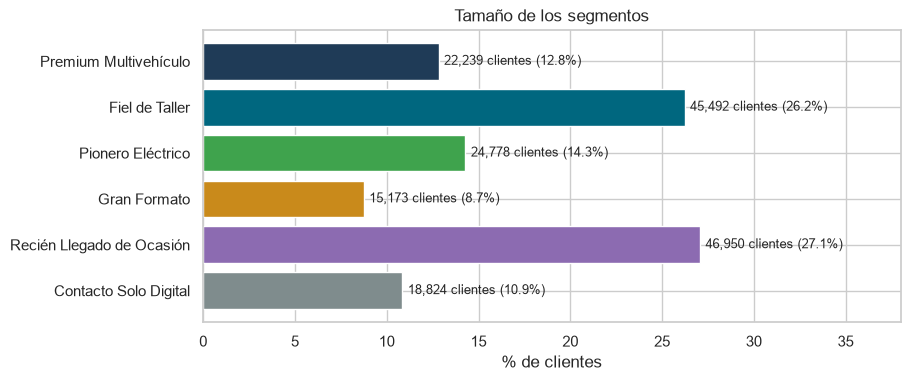

In [3]:
tam = clientes["segmento"].value_counts().reindex(ORDEN)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(ORDEN, tam / len(clientes) * 100, color=[COLORES[s] for s in ORDEN])
for i, n in enumerate(tam):
    ax.text(n / len(clientes) * 100 + .3, i, f"{n:,} clientes ({n / len(clientes):.1%})", va="center", fontsize=9)
ax.invert_yaxis()
ax.set(title="Tamaño de los segmentos", xlabel="% de clientes", xlim=(0, 38))
plt.show()

### 2.2 Tabla de perfilado (unidades reales)

Cada columna es un segmento y la última es la **media de toda la base**, para comparar.

In [4]:
def perfil(g):
    fin = g["finance_leasing_status"]
    return pd.Series({
        "clientes": len(g),
        "% de la base": len(g) / len(clientes) * 100,
        "— Relación con la marca —": np.nan,
        "meses como cliente (mediana)": g["meses_cliente"].median(),
        "vehículos en el histórico (media)": g["n_vehiculos_historico"].mean(),
        "% con 2+ vehículos actuales": (g["n_vehiculos_actuales"] >= 2).mean() * 100,
        "% sin vehículo actual (inactivos)": (g["n_vehiculos_actuales"] == 0).mean() * 100,
        "% leasing activo": fin.str.startswith("active").mean() * 100,
        "% nunca ha financiado": (fin == "never_active").mean() * 100,
        "— Vehículo —": np.nan,
        "antigüedad del vehículo (años, mediana)": g["antiguedad_vehiculo"].median(),
        "% con vehículo de 6+ años": (g["antiguedad_vehiculo"] >= 6).mean() * 100,
        "% gama alta o lujo (nivel 3-4)": (g["gama_max"] >= 3).mean() * 100,
        "% con algún AMG": (g["pct_amg"] > 0).mean() * 100,
        "% de vehículos electrificados": g["pct_electrificado"].mean() * 100,
        "% de vehículos furgoneta": g["pct_furgoneta"].mean() * 100,
        "— Taller —": np.nan,
        "visitas en garantía por vehículo (mediana)": g["visitas_taller_por_vehiculo"].median(),
        "percentil de visitas en su país (media)": g["visitas_taller_pct_pais"].mean(),
        "— Contacto —": np.nan,
        "% consiente teléfono": g["consent_phone"].mean() * 100,
        "% consiente email": g["consent_email"].mean() * 100,
        "% consiente correo postal": g["consent_post"].mean() * 100,
        "— Persona y zona —": np.nan,
        "% 45 años o más": g["age_range"].isin(["45-54", "55-64", "65+"]).mean() * 100,
        "% menores de 35": g["age_range"].isin(["<25", "25-34"]).mean() * 100,
        "% hombre (inferido)": (g["gender_derived"] == "male").mean() * 100,
        "% mujer (inferido)": (g["gender_derived"] == "female").mean() * 100,
        "% género desconocido": (g["gender_derived"] == "unknown").mean() * 100,
        "% Suiza": (g["country_code"] == "CH").mean() * 100,
        "% con relación B2B": g["es_b2b"].mean() * 100,
        "percentil de poder adquisitivo en su país (media)": g["poder_adquisitivo_pct_pais"].mean(),
    })

tabla = clientes.groupby("segmento", observed=True).apply(perfil).T[ORDEN]
tabla["TOTAL BASE"] = perfil(clientes)
tabla.round(1).astype(object).where(tabla.notna(), "")

segmento,Premium Multivehículo,Fiel de Taller,Pionero Eléctrico,Gran Formato,Recién Llegado de Ocasión,Contacto Solo Digital,TOTAL BASE
clientes,"22,239.0","45,492.0","24,778.0","15,173.0","46,950.0","18,824.0","173,456.0"
% de la base,12.8,26.2,14.3,8.7,27.1,10.9,100.0
— Relación con la marca —,,,,,,,
meses como cliente (mediana),50.0,42.0,26.0,26.0,20.0,35.0,36.0
vehículos en el histórico (media),5.6,1.2,1.2,1.3,1.1,1.3,1.7
% con 2+ vehículos actuales,49.4,1.8,1.8,5.5,1.2,4.6,8.4
% sin vehículo actual (inactivos),2.4,6.4,11.0,10.8,17.6,10.5,10.4
% leasing activo,58.3,25.7,29.5,21.1,12.1,24.2,26.2
% nunca ha financiado,36.9,70.5,67.4,76.1,85.4,73.0,70.6
— Vehículo —,,,,,,,


### 2.3 ¿Qué distingue a cada segmento?

Diferencia de cada segmento respecto a la media de la base, en **desviaciones estándar** (las features escaladas del
modelo). Rojo = por encima de la media; azul = por debajo. Es la "huella" de cada segmento.

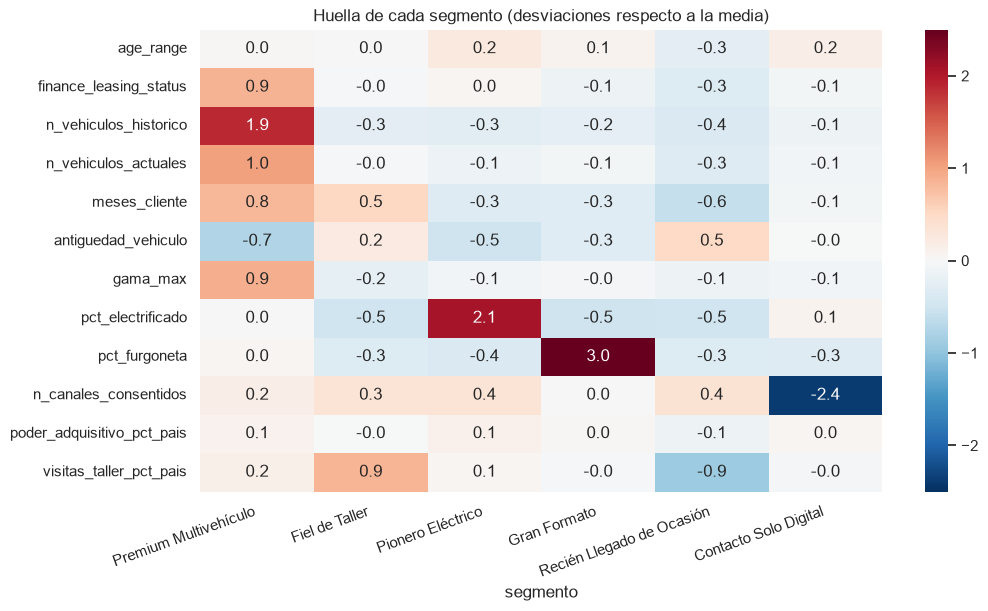

In [5]:
huella = X.groupby(clientes["segmento"], observed=True).mean().T[ORDEN]
plt.figure(figsize=(11, 6))
sns.heatmap(huella, cmap="RdBu_r", center=0, vmin=-2.5, vmax=2.5, annot=True, fmt=".1f")
plt.title("Huella de cada segmento (desviaciones respecto a la media)")
plt.xticks(rotation=20, ha="right")
plt.show()

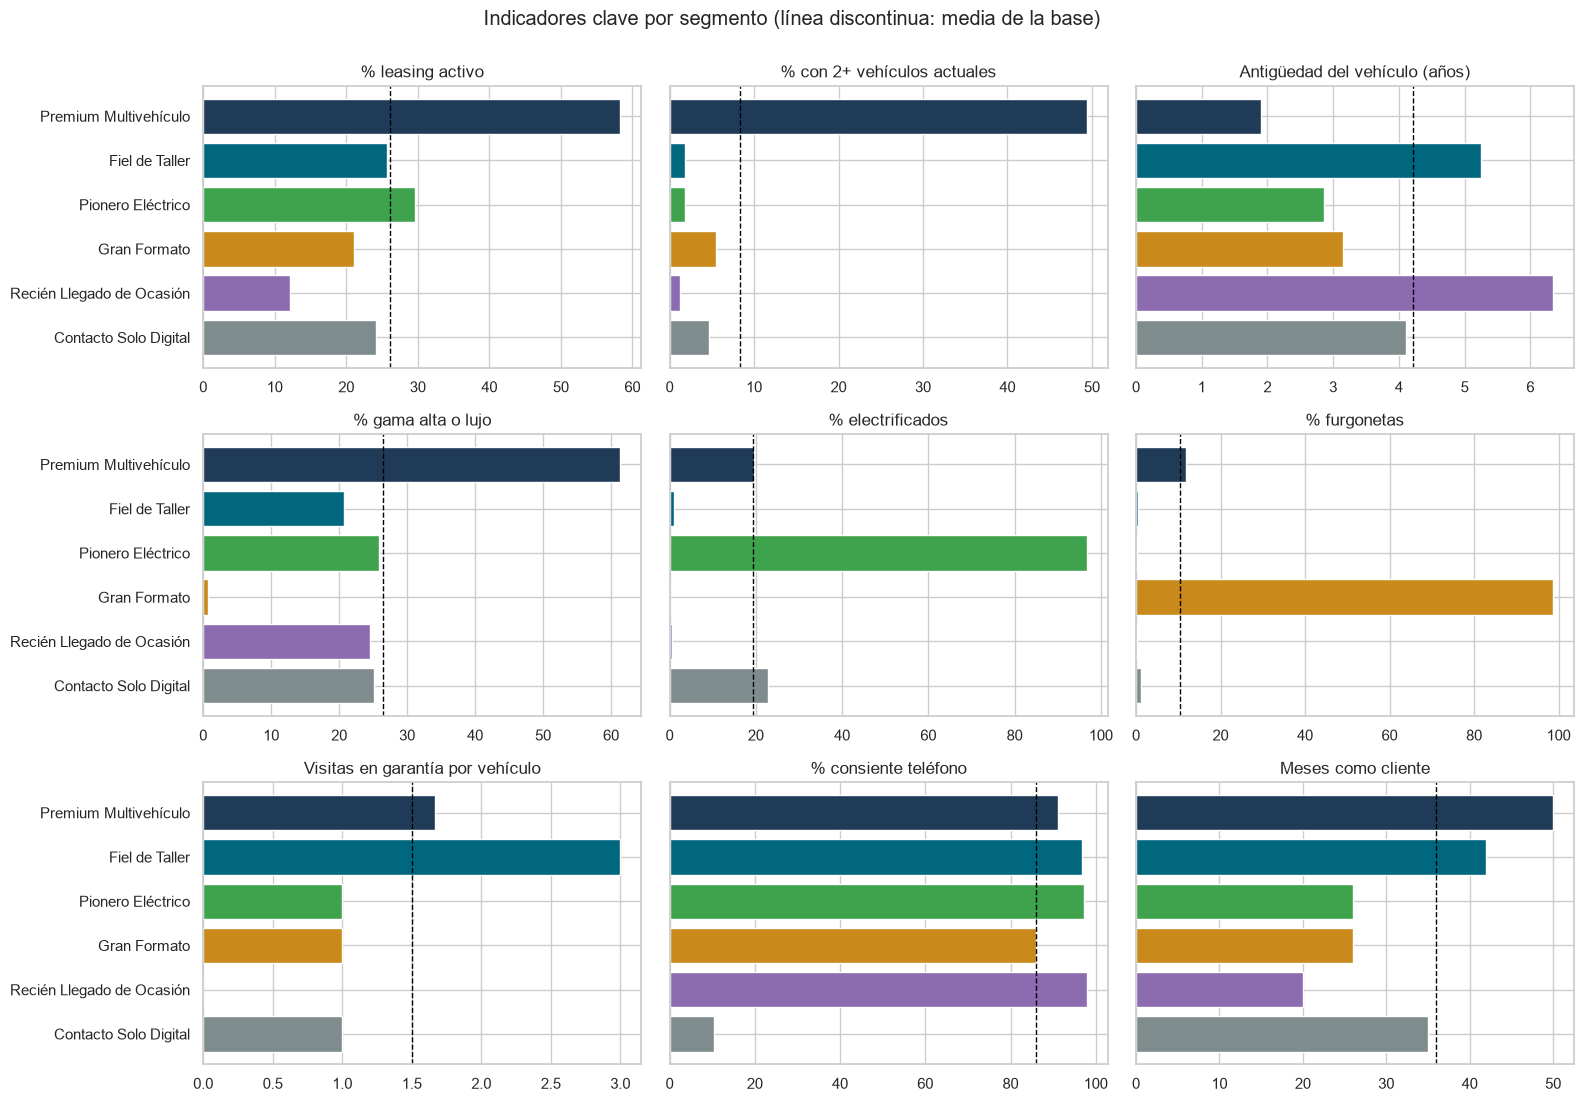

In [6]:
indicadores = {
    "% leasing activo": "% leasing activo",
    "% con 2+ vehículos actuales": "% con 2+ vehículos actuales",
    "antigüedad del vehículo (años, mediana)": "Antigüedad del vehículo (años)",
    "% gama alta o lujo (nivel 3-4)": "% gama alta o lujo",
    "% de vehículos electrificados": "% electrificados",
    "% de vehículos furgoneta": "% furgonetas",
    "visitas en garantía por vehículo (mediana)": "Visitas en garantía por vehículo",
    "% consiente teléfono": "% consiente teléfono",
    "meses como cliente (mediana)": "Meses como cliente",
}
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, (fila, titulo) in zip(axes.flat, indicadores.items()):
    vals = tabla.loc[fila, ORDEN].astype(float)
    ax.barh(ORDEN, vals, color=[COLORES[s] for s in ORDEN])
    ax.axvline(float(tabla.loc[fila, "TOTAL BASE"]), color="black", ls="--", lw=1)
    ax.invert_yaxis()
    ax.set_title(titulo)
    if ax not in axes[:, 0]:
        ax.set_yticklabels([])
fig.suptitle("Indicadores clave por segmento (línea discontinua: media de la base)", y=1.0)
plt.tight_layout()
plt.show()

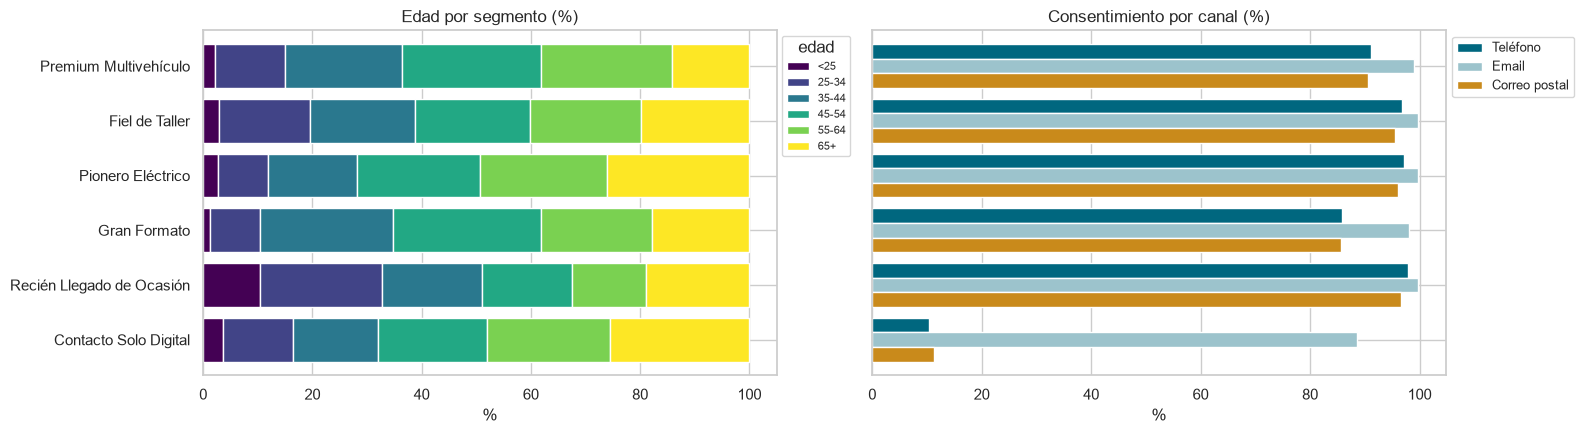

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
edad = pd.crosstab(clientes["segmento"], clientes["age_range"], normalize="index")[ORDEN_EDAD].mul(100)
edad.plot.barh(stacked=True, ax=axes[0], colormap="viridis", width=.8)
axes[0].invert_yaxis()
axes[0].set(title="Edad por segmento (%)", xlabel="%", ylabel="")
axes[0].legend(title="edad", bbox_to_anchor=(1, 1), fontsize=8)
canal = clientes.groupby("segmento", observed=True)[["consent_phone", "consent_email", "consent_post"]].mean().mul(100)
canal.columns = ["Teléfono", "Email", "Correo postal"]
canal.plot.barh(ax=axes[1], color=["#00677F", "#9cc3cc", "#c98a1b"], width=.8)
axes[1].invert_yaxis()
axes[1].set(title="Consentimiento por canal (%)", xlabel="%", ylabel="")
axes[1].set_yticklabels([])
axes[1].legend(bbox_to_anchor=(1, 1), fontsize=9)
plt.tight_layout()
plt.show()

In [8]:
# Modelos y motorización de los vehículos de cada segmento (todas sus relaciones)
veh = df[["client_id", "model_class", "engine_concept"]].merge(clientes[["segmento"]], left_on="client_id", right_index=True)
top_modelos = (veh.groupby("segmento", observed=True)["model_class"]
                  .apply(lambda s: ", ".join(f"{m} ({p:.0f} %)" for m, p in s.value_counts(normalize=True).mul(100).head(4).items())))
motor = pd.crosstab(veh["segmento"], veh["engine_concept"].fillna("UNKNOWN"), normalize="index").mul(100)
display(top_modelos.rename("modelos más frecuentes").to_frame())
motor[["COMBUSTION", "MILD_HYBRID", "PLUGIN_HYBRID", "ELECTRIC", "UNKNOWN"]].round(0)

,modelos más frecuentes
segmento,
Premium Multivehículo,"GLC-Class (13 %), V-Class / Vito (11 %), C-Cla..."
Fiel de Taller,"B-/GLA-/GLB-Class (18 %), GLC-Class (17 %), A-..."
Pionero Eléctrico,"GLC-Class (24 %), EQA-/EQB-Class (23 %), GLE-/..."
Gran Formato,"V-Class / Vito (69 %), Sprinter (20 %), Citan ..."
Recién Llegado de Ocasión,"A-Class (18 %), C-Class (18 %), GLC-Class (15 ..."
Contacto Solo Digital,"GLC-Class (19 %), C-Class (13 %), B-/GLA-/GLB-..."


engine_concept,COMBUSTION,MILD_HYBRID,PLUGIN_HYBRID,ELECTRIC,UNKNOWN
segmento,,,,,
Premium Multivehículo,32.0,8.0,7.0,7.0,46.0
Fiel de Taller,37.0,15.0,1.0,1.0,48.0
Pionero Eléctrico,2.0,1.0,35.0,33.0,29.0
Gran Formato,55.0,0.0,0.0,0.0,44.0
Recién Llegado de Ocasión,41.0,12.0,0.0,0.0,46.0
Contacto Solo Digital,29.0,11.0,8.0,8.0,43.0


## 3. Trampas de interpretación (comprobadas antes de poner nombres)

### 3.1 ¿Las visitas al taller reflejan al cliente o la edad de su coche?

En el Reto 1 vimos que las visitas en garantía dependen de la edad del coche: suben hasta ~5 años y luego bajan.
"Fiel de Taller" tiene coches de ~5 años (pico de visitas) y "Recién Llegado de Ocasión" coches de ~6 años (fuera de
garantía). Si la diferencia se debiera solo a eso, los nombres estarían mal. Comparamos **coches de la misma edad**.

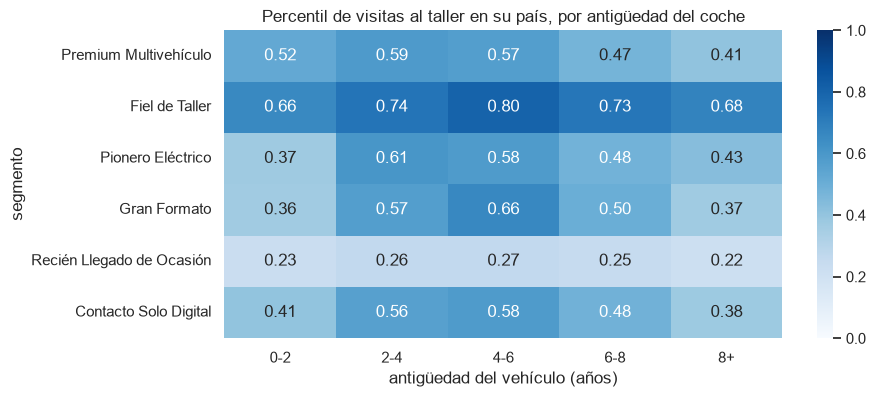

In [9]:
clientes["banda_antigüedad"] = pd.cut(clientes["antiguedad_vehiculo"], [-1, 2, 4, 6, 8, 50],
                                      labels=["0-2", "2-4", "4-6", "6-8", "8+"])
piv = clientes.pivot_table(index="segmento", columns="banda_antigüedad", values="visitas_taller_pct_pais",
                           aggfunc="mean", observed=True)
plt.figure(figsize=(9, 4))
sns.heatmap(piv, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Percentil de visitas al taller en su país, por antigüedad del coche")
plt.xlabel("antigüedad del vehículo (años)")
plt.show()

**Resultado:** con coches de la **misma edad**, "Fiel de Taller" tiene más visitas en **todas** las bandas (percentil
0,66-0,80) y "Recién Llegado de Ocasión" menos en todas (0,22-0,27). La diferencia es de **comportamiento**, no de edad
del coche. Los nombres se sostienen.

### 3.2 "Recién Llegado de Ocasión": ¿segunda mano? (hipótesis)

Si el coche es bastante más antiguo que la relación del cliente con la marca, probablemente lo compró **usado**.

In [10]:
clientes["coche_anterior_a_la_relacion"] = clientes["antiguedad_vehiculo"] * 12 > clientes["meses_cliente"] + 12
(clientes.groupby("segmento", observed=True)["coche_anterior_a_la_relacion"].mean().mul(100)
   .rename("% con coche >1 año más antiguo que su relación con la marca").to_frame())

,% con coche >1 año más antiguo que su relación con la marca
segmento,
Premium Multivehículo,9.9
Fiel de Taller,50.2
Pionero Eléctrico,32.6
Gran Formato,37.9
Recién Llegado de Ocasión,81.2
Contacto Solo Digital,49.6


El **81 %** de este segmento tiene un coche más de un año anterior a su relación con la marca (10 % en Premium
Multivehículo). Junto con que casi nunca financian (85 %) y apenas usan el taller oficial, apunta a una **entrada por
el mercado de ocasión**.

⚠️ **Es una hipótesis.** `months_as_mb_customer` cuenta desde la **primera conexión** del cliente a un coche, no desde la
compra. Otra explicación posible: clientes que activaron tarde los servicios conectados. **Cómo validarlo:** cruzar con
el registro de ventas (nuevo / usado / concesionario) antes de lanzar campañas basadas en ello.

### 3.3 "Contacto Solo Digital": ¿son clientes no contactables?

In [11]:
seg_digital = clientes[clientes["segmento"] == "Contacto Solo Digital"]
pd.Series({
    "% solo email (1 canal = email)": ((seg_digital["n_canales_consentidos"] == 1) & seg_digital["consent_email"]).mean() * 100,
    "% con 0 canales": (seg_digital["n_canales_consentidos"] == 0).mean() * 100,
    "% consiente teléfono": seg_digital["consent_phone"].mean() * 100,
    "% consiente correo postal": seg_digital["consent_post"].mean() * 100,
}).round(1)

% solo email (1 canal = email)   78.7
% con 0 canales                   0.0
% consiente teléfono             10.4
% consiente correo postal        11.2
dtype: float64

No: el 89 % acepta **email** (el 79 % **solo** email) y ninguno tiene 0 canales; lo que falta es teléfono (10 %) y
correo postal (11 %). El resto de su perfil (edad, gama, vehículos,
taller) está **cerca de la media**: es un segmento de **canal**, no de tipo de cliente. Su valor para marketing es
operativo: a estos clientes solo se les puede llegar por email, así que cualquier campaña telefónica o postal los excluye.

### 3.4 Variables que NO diferencian a los segmentos

In [12]:
no_dif = pd.DataFrame({
    "percentil de poder adquisitivo (media)": clientes.groupby("segmento", observed=True)["poder_adquisitivo_pct_pais"].mean(),
    "distancia media por trayecto, km (mediana)": clientes.groupby("segmento", observed=True)["trip_distance_average"].median(),
    "velocidad media, km/h (mediana)": clientes.groupby("segmento", observed=True)["speed_average"].median(),
    "% con poder adquisitivo imputado": clientes.groupby("segmento", observed=True)["poder_adquisitivo_hogar_eur"].apply(lambda s: s.isna().mean() * 100),
    "% con 36 meses exactos (artefacto)": clientes.groupby("segmento", observed=True)["meses_cliente"].apply(lambda s: (s == 36).mean() * 100),
    "% con telemetría*": clientes.groupby("segmento", observed=True)["tiene_telemetria"].mean() * 100,
})
no_dif.loc["TOTAL BASE"] = [clientes["poder_adquisitivo_pct_pais"].mean(), clientes["trip_distance_average"].median(),
                            clientes["speed_average"].median(), clientes["poder_adquisitivo_hogar_eur"].isna().mean() * 100,
                            (clientes["meses_cliente"] == 36).mean() * 100, clientes["tiene_telemetria"].mean() * 100]
no_dif.round(2)

,percentil de poder adquisitivo (media),"distancia media por trayecto, km (mediana)","velocidad media, km/h (mediana)",% con poder adquisitivo imputado,% con 36 meses exactos (artefacto),% con telemetría*
segmento,,,,,,
Premium Multivehículo,0.5,14.6,49.7,1.9,11.7,73.5
Fiel de Taller,0.5,13.6,49.0,2.9,15.5,70.9
Pionero Eléctrico,0.5,13.6,49.5,11.9,5.5,62.5
Gran Formato,0.5,15.6,51.4,14.6,7.8,61.2
Recién Llegado de Ocasión,0.5,14.2,48.9,14.8,13.2,51.9
Contacto Solo Digital,0.5,14.2,50.0,8.1,14.6,33.6
TOTAL BASE,0.5,14.1,49.4,8.8,12.2,60.0


- **Poder adquisitivo de la zona**: igual en todos los segmentos (≈ 0,5, la mediana). El carácter premium de un
  segmento viene de **lo que conduce** (gama, AMG), no de dónde vive. No se debe vender "Premium Multivehículo" como
  "zonas ricas".
- **Conducción** (km por trayecto, velocidad): prácticamente igual en todos. La telemetría no habría ayudado a segmentar.
- **Poder adquisitivo imputado**: oscila entre el 2 % y el 15 % según el segmento. En los segmentos con más imputados
  (Recién Llegado, Gran Formato, Pionero Eléctrico) la media está algo "comprimida" hacia 0,5.
- **Artefacto de 36 meses** (Reto 1): está repartido (6-16 %) y no domina ningún segmento.
- *Telemetría: solo descriptiva y sesgada (los eléctricos no la tienen); no se usa para interpretar.

### 3.5 Género: precaución

El género es **inferido** y desconocido en un 4-29 % según el segmento (29 % en Recién Llegado de Ocasión). Las
diferencias de género entre segmentos **no se usan para definir campañas**: solo "Premium Multivehículo" destaca
(81 % hombre, con solo un 4 % desconocido).

## 4. Sub-perfiles de "Premium Multivehículo"

En el Reto 3 este fue el segmento menos cohesionado (silhouette 0,05, 40 % de clientes en la frontera). Por dentro
mezcla tres situaciones: varios coches a la vez, leasing activo y flotas.

In [13]:
prem = clientes["segmento"] == "Premium Multivehículo"
cp = clientes[prem]
multi, leasing = cp["n_vehiculos_actuales"] >= 2, cp["finance_leasing_status"].str.startswith("active")
pd.Series({
    "solo multivehículo (2+ actuales, sin leasing)": (multi & ~leasing).mean() * 100,
    "solo leasing activo (<2 actuales)": (~multi & leasing).mean() * 100,
    "multivehículo y leasing": (multi & leasing).mean() * 100,
    "ninguno de los dos (histórico amplio)": (~multi & ~leasing).mean() * 100,
    "flota (>10 vehículos en el histórico)": (cp["n_vehiculos_historico"] > 10).mean() * 100,
}, name="% del segmento").round(1).to_frame()

,% del segmento
"solo multivehículo (2+ actuales, sin leasing)",23.6
solo leasing activo (<2 actuales),32.5
multivehículo y leasing,25.8
ninguno de los dos (histórico amplio),18.1
flota (>10 vehículos en el histórico),7.5


Para separarlo con criterio, aplicamos un **K-Means solo dentro de este segmento** (mismas features, mismo
preprocesado), con 50 inicializaciones, y comparamos k = 2 a 5.

In [14]:
Xp = X[prem]
sub_res = {}
for k in range(2, 6):
    m = KMeans(n_clusters=k, n_init=N_INIT_FINAL, random_state=SEMILLA).fit(Xp)
    otra = KMeans(n_clusters=k, n_init=N_INIT_FINAL, random_state=7).fit_predict(Xp)
    sub_res[k] = {"silhouette": f"{silhouette_score(Xp, m.labels_, sample_size=15_000, random_state=0):.3f}",
                  "ARI entre semillas": f"{adjusted_rand_score(m.labels_, otra):.3f}",
                  "tamaños (%)": " / ".join(f"{p:.0f}" for p in np.bincount(m.labels_) / len(Xp) * 100)}
    if k == 3:
        sub_km = m
pd.DataFrame(sub_res).T

,silhouette,ARI entre semillas,tamaños (%)
2,0.229,1.000,23 / 77
3,0.162,0.999,50 / 16 / 34
4,0.167,1.000,8 / 30 / 12 / 49
5,0.117,0.999,29 / 26 / 8 / 11 / 25


- **k = 2** tiene el mejor silhouette (0,23), pero junta a los clientes en leasing con los que compran al contado, dos
  públicos que piden ofertas distintas.
- **k = 3** (silhouette 0,16, más del triple que el del segmento completo, y totalmente estable entre semillas)
  separa tres sub-perfiles con una acción comercial distinta.
- **k = 4** tiene un silhouette prácticamente igual (0,167), pero crea un sub-grupo del 8 % del segmento (~1.800
  clientes), demasiado pequeño para una campaña propia. A partir de k = 5 el silhouette cae.

**Elegimos k = 3**, con el mismo criterio de accionabilidad del Reto 3.

In [15]:
cen_sub = pd.DataFrame(sub_km.cluster_centers_, columns=X.columns)
nombres_sub = {cen_sub["n_vehiculos_historico"].idxmax(): "Gran Cuenta / Flota"}
resto_sub = cen_sub.drop(index=list(nombres_sub))
nombres_sub[resto_sub["finance_leasing_status"].idxmax()] = "Renovador en Leasing"
nombres_sub[resto_sub["finance_leasing_status"].idxmin()] = "Premium al Contado"
cp = cp.assign(subperfil=pd.Series(sub_km.labels_, index=cp.index).map(nombres_sub))
ORDEN_SUB = ["Renovador en Leasing", "Premium al Contado", "Gran Cuenta / Flota"]

def perfil_sub(g):
    return pd.Series({
        "% del segmento": len(g) / len(cp) * 100,
        "clientes": len(g),
        "% leasing activo": g["finance_leasing_status"].str.startswith("active").mean() * 100,
        "vehículos en el histórico (mediana)": g["n_vehiculos_historico"].median(),
        "vehículos actuales (mediana)": g["n_vehiculos_actuales"].median(),
        "% gama alta o lujo": (g["gama_max"] >= 3).mean() * 100,
        "% con algún AMG": (g["pct_amg"] > 0).mean() * 100,
        "% de vehículos furgoneta": g["pct_furgoneta"].mean() * 100,
        "% con relación B2B": g["es_b2b"].mean() * 100,
        "antigüedad del vehículo (mediana)": g["antiguedad_vehiculo"].median(),
        "meses como cliente (mediana)": g["meses_cliente"].median(),
        "% 45 años o más": g["age_range"].isin(["45-54", "55-64", "65+"]).mean() * 100,
    })
cp.groupby("subperfil").apply(perfil_sub).T[ORDEN_SUB]

subperfil,Renovador en Leasing,Premium al Contado,Gran Cuenta / Flota
% del segmento,50.1,34.3,15.6
clientes,"11,135.0","7,637.0","3,467.0"
% leasing activo,98.3,0.1,57.9
vehículos en el histórico (mediana),2.0,3.0,8.0
vehículos actuales (mediana),1.0,2.0,3.0
% gama alta o lujo,48.4,74.3,74.4
% con algún AMG,32.4,36.6,48.0
% de vehículos furgoneta,6.4,10.0,33.6
% con relación B2B,0.4,1.4,7.7
antigüedad del vehículo (mediana),1.8,2.5,0.9


## 5. Fichas de segmento para marketing

Las cifras de cada ficha salen de la tabla del apartado 2.2.

---

### 🔷 Premium Multivehículo · 12,8 % (22.239 clientes)
**Quién es:** el cliente de **mayor valor**. Mediana de 3 Mercedes en su historia, la mitad con 2 o más a la vez, un
58 % con leasing activo, coches muy nuevos (mediana < 2 años), un 61 % con gama alta o lujo y un 36 % con algún AMG.
Es el más antiguo como cliente (50 meses) y casi nunca está inactivo (2 %).
**Sub-perfiles:** *Renovador en Leasing* (~50 %), *Premium al Contado* (~34 %) y *Gran Cuenta / Flota* (~16 %).
- **Oferta de vehículos:** renovación anticipada antes del fin del leasing (Renovador); preestrenos de gama alta y AMG
  (Al Contado); condiciones de flota y furgonetas (Gran Cuenta).
- **Mantenimiento:** paquetes multi-vehículo con un único contrato.
- **Fidelización:** programa de cliente preferente, eventos de marca.
- **Comunicación:** gestor personal; todos los canales disponibles (teléfono 91 %).

### 🔷 Fiel de Taller · 26,2 % (45.492 clientes)
**Quién es:** el segmento más grande junto con Recién Llegado. Cliente veterano (42 meses) con un coche, casi siempre
compacto o medio (A, B/GLA/GLB, C, GLC), de combustión y de unos 5 años. Su rasgo distintivo: **usa el taller oficial
mucho más que la media** de su país, también comparando coches de la misma edad. Más presente en Suiza (74 %).
- **Oferta de vehículos:** su coche entra en edad de renovación (37 % con 6+ años). Ofertas de cambio con valoración
  de su coche actual.
- **Mantenimiento:** **público principal** de los planes de mantenimiento y de la garantía extendida, porque su
  garantía está terminando.
- **Fidelización:** convertir la confianza en el taller en fidelidad de compra.
- **Comunicación:** teléfono (97 %) y correo postal (96 %); el taller como punto de contacto.

### 🔷 Pionero Eléctrico · 14,3 % (24.778 clientes)
**Quién es:** el 97 % de sus vehículos son **híbridos enchufables o eléctricos** (EQA/EQB, GLC híbrido, EQC, EQE…). Coches
muy nuevos (mediana 2,9 años), cliente reciente (26 meses) y con más peso de Austria (45 %, frente al 34 % de la base).
Un 30 % tiene leasing activo.
- **Oferta de vehículos:** nuevas gamas EQ, paso de híbrido enchufable a 100 % eléctrico.
- **Mantenimiento:** planes específicos de batería y software.
- **Fidelización:** servicios de carga, actualizaciones remotas.
- **Comunicación:** digital y teléfono (97 %).

### 🔷 Gran Formato · 8,7 % (15.173 clientes)
**Quién es:** casi todos sus vehículos son **furgonetas**: V-Class/Vito (69 %), Sprinter (20 %) y Citan (7 %). Coches
nuevos (3 años) y combustión. Pese a ser furgonetas, solo el 3 % son relaciones de empresa: son mayoritariamente
**particulares** (familias numerosas, ocio, autónomos registrados como particulares).
- **Oferta de vehículos:** nuevas V-Class y eVito/eSprinter; versiones camper.
- **Mantenimiento:** planes con vehículo de sustitución (para ellos la furgoneta suele ser imprescindible).
- **Fidelización:** accesorios y equipamiento.
- **Comunicación:** teléfono (86 %) y correo postal (86 %), algo por debajo del resto.

### 🔷 Recién Llegado de Ocasión · 27,1 % (46.950 clientes)
**Quién es:** el cliente **más reciente** (20 meses) y el de **perfil más joven** (33 % menores de 35, frente al ~20 % de
la base), aunque la mitad tiene 45 años o más. Coche **antiguo** (mediana 6,3 años; el 54 % con 6+ años), casi nunca ha
financiado (85 %), **no usa el taller oficial** (mediana de 0 visitas) y un 18 % ya no tiene vehículo conectado.
Hipótesis: **entró en la marca con un coche de ocasión** (ver 3.2).
- **Oferta de vehículos:** **primer Mercedes nuevo** o seminuevo certificado, con financiación de entrada.
- **Mantenimiento:** atraerlo al taller oficial con una primera revisión o un diagnóstico gratuitos.
- **Fidelización:** es el segmento con **mayor riesgo de abandono** (18 % inactivos). Bienvenida y onboarding.
- **Comunicación:** teléfono (98 %) y postal (97 %). Atención: un 29 % sin género conocido y un 15 % sin dato de zona.

### 🔷 Contacto Solo Digital · 10,9 % (18.824 clientes)
**Quién es:** su perfil de cliente está **en la media** (edad, gama, vehículos), pero acepta muy pocos canales: el 79 %
**solo email** (email 89 %, teléfono 10 %, postal 11 %). Es un segmento de **canal**: indica *cómo* se puede contactar, no *qué* ofrecer.
- **Acción prioritaria:** campañas de **recaptación de consentimiento** (por email y en el taller o el concesionario).
- **Comunicación:** sobre todo email y app. Cualquier campaña por teléfono o correo postal no llega a este 11 % de
  la base.
- **Oferta y mantenimiento:** según su vehículo (un 23 % de sus coches son electrificados), con las ofertas del segmento
  al que más se parezca.

## 6. Resumen

| Segmento | % | Rasgo clave | Prioridad comercial |
|---|---|---|---|
| Premium Multivehículo | 12,8 % | Varios coches, leasing, gama alta | Retener y renovar (mayor valor) |
| Fiel de Taller | 26,2 % | Usa mucho el taller oficial, coche de ~5 años | Planes de mantenimiento y renovación |
| Pionero Eléctrico | 14,3 % | 97 % electrificado, coches nuevos | Gama EQ y servicios eléctricos |
| Gran Formato | 8,7 % | Furgonetas (V-Class/Vito, Sprinter), particulares | Renovación de furgoneta, eVans |
| Recién Llegado de Ocasión | 27,1 % | Reciente, coche antiguo, sin taller oficial | Primer coche nuevo, atraer al taller, evitar abandono |
| Contacto Solo Digital | 10,9 % | Solo consiente email | Recaptar consentimientos; solo canal digital |

**Hallazgos de interpretación:**
- Las diferencias de taller son de **comportamiento**, no de la edad del coche (comprobado en coches de la misma edad).
- El poder adquisitivo de la zona y la forma de conducir **no diferencian** segmentos.
- "Recién Llegado de Ocasión" se basa en una **hipótesis** que conviene validar con datos de ventas.
- "Contacto Solo Digital" es un segmento de **canal**: se combina con las ofertas de los demás.
- "Premium Multivehículo" se divide en 3 sub-perfiles estables para afinar campañas.